# Parkha Kashaf Zeb
# 11/19/2026
# Part B: End-to-End Tabular ML Baseline

## 1. Project Overview

The objective of Part B is to develop a reproducible machine learning workflow using Pakistan's Largest E-Commerce Dataset.

The workflow will cover problem definition, data preparation, preprocessing, model training, evaluation, error analysis, and predictions on unseen records.

## 2. Dataset

**Dataset:** Pakistan's Largest E-Commerce Dataset

**Source:** Cleaned dataset generated in Part A.

**File:** `outputs/processed/pakistan_ecommerce_cleaned.csv`

## 3. Proposed Prediction Problem

**Proposed Target:** `status`

**Proposed Problem Type:** Binary Classification

The initial idea is to predict whether an order item will be completed or canceled.

- Complete
- Canceled

The final target selection will be confirmed after inspecting the target distribution and checking for potential data leakage.

## 4. Intended Use

The proposed model aims to help e-commerce businesses estimate order completion or cancellation outcomes using information available before the final order status is known.

## 5. Machine Learning Workflow

1. Inspect the dataset and target variable.
2. Identify potential data leakage.
3. Select relevant features and target.
4. Split the data into training and testing sets.
5. Build a preprocessing pipeline using Scikit-learn.
6. Train a baseline model and at least two candidate models.
7. Evaluate and compare model performance.
8. Perform error analysis.
9. Save the fitted pipeline and test it on unseen records.
10. Document assumptions, intended use, limitations, and risks.

## 6. Dataset Inspection

In this step, the cleaned dataset from Part A is loaded and inspected to understand its structure, available features, and target variable before building the machine learning model.

In [2]:
import pandas as pd
import numpy as np

df = pd.read_csv(
    "../outputs/processed/pakistan_ecommerce_cleaned.csv",
    low_memory=False
)

print("Dataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

Dataset Shape: (584524, 21)

Column Names:
['item_id', 'status', 'created_at', 'sku', 'price', 'qty_ordered', 'grand_total', 'increment_id', 'category_name_1', 'sales_commission_code', 'discount_amount', 'payment_method', 'Working Date', 'BI Status', ' MV ', 'Year', 'Month', 'Customer Since', 'M-Y', 'FY', 'Customer ID']

Data Types:
item_id                    int64
status                       str
created_at                   str
sku                          str
price                    float64
qty_ordered                int64
grand_total              float64
increment_id                 str
category_name_1              str
sales_commission_code        str
discount_amount          float64
payment_method               str
Working Date                 str
BI Status                    str
 MV                          str
Year                       int64
Month                      int64
Customer Since               str
M-Y                          str
FY                           str
Custo

In [2]:
print("Target Variable Distribution:")
print(df["status"].value_counts(dropna=False))

Target Variable Distribution:
status
complete          233685
canceled          201249
received           77290
order_refunded     59529
refund              8050
cod                 2859
paid                1159
closed               494
payment_review        57
pending               48
processing            33
holded                31
NaN                   19
fraud                 10
pending_paypal         7
exchange               4
Name: count, dtype: int64


## 7. Target Selection

For this baseline experiment, the target variable is `status`.

Only records with `complete` and `canceled` statuses will be included. Other statuses and missing target values will be excluded.

This makes the task a binary classification problem. The model will estimate whether an order item belongs to the completed or canceled category.

In [3]:
# Keep only the two selected target classes
model_df = df[df["status"].isin(["complete", "canceled"])].copy()

print("Filtered Dataset Shape:", model_df.shape)

print("\nTarget Distribution:")
print(model_df["status"].value_counts())

print("\nTarget Percentages:")
print(
    model_df["status"].value_counts(normalize=True).mul(100).round(2)
)

Filtered Dataset Shape: (434934, 21)

Target Distribution:
status
complete    233685
canceled    201249
Name: count, dtype: int64

Target Percentages:
status
complete    53.73
canceled    46.27
Name: proportion, dtype: float64


In [ ]:
#Check order-level grouping
order_status_counts = model_df.groupby("increment_id")["status"].nunique()

print("Total Unique Orders:", model_df["increment_id"].nunique())

print(
    "Orders with Multiple Statuses:",
    (order_status_counts > 1).sum()
)

print(
    "Orders with Multiple Items:",
    (model_df.groupby("increment_id").size() > 1).sum()
)

Total Unique Orders: 318158
Orders with Multiple Statuses: 0
Orders with Multiple Items: 56308


### Target Selection and Class Distribution

The target variable selected for this classification task is `status`.

Only records with the statuses `complete` and `canceled` are retained. Other statuses are excluded because this project focuses on distinguishing completed orders from canceled orders.

The filtered dataset contains 434,934 records:
- Complete: 233,685 (53.73%)
- Canceled: 201,249 (46.27%)

The target classes are reasonably balanced, so no immediate resampling is required.

The dataset contains multiple item records belonging to the same order. Therefore, a group-based data split using `increment_id` will be considered to prevent records from the same order appearing in both training and testing sets.

No orders with multiple statuses were identified in the filtered dataset.

In [6]:
# Check how many item records belong to each order
items_per_order = model_df.groupby("increment_id").size()

print("Total Unique Orders:", items_per_order.count())
print("Orders with One Item:", (items_per_order == 1).sum())
print("Orders with Multiple Items:", (items_per_order > 1).sum())

print("\nMaximum Items in One Order:", items_per_order.max())
print("\nItems per Order Distribution:")
print(items_per_order.describe())

Total Unique Orders: 318158
Orders with One Item: 261850
Orders with Multiple Items: 56308

Maximum Items in One Order: 72

Items per Order Distribution:
count    318158.000000
mean          1.367038
std           1.168174
min           1.000000
25%           1.000000
50%           1.000000
75%           1.000000
max          72.000000
dtype: float64


## 8. Order-Level Structure and Data Leakage Consideration

The dataset contains 434,934 item-level records representing 318,158 unique orders.

A total of 56,308 orders contain multiple item records, while 261,850 orders contain only one item. Each order contains an average of approximately 1.37 items, with a maximum of 72 items.

Since multiple records can belong to the same order, a random row-level split could cause data leakage. Records belonging to the same order must remain in the same dataset partition.

Therefore, `increment_id` will be used as the grouping variable during train-test splitting. It will not be used as a model feature.

In [8]:
print("Available Features:")
for col in model_df.columns:
    print(col)

Available Features:
item_id
status
created_at
sku
price
qty_ordered
grand_total
increment_id
category_name_1
sales_commission_code
discount_amount
payment_method
Working Date
BI Status
 MV 
Year
Month
Customer Since
M-Y
FY
Customer ID


In [10]:
# Inspect potentially unclear or duplicated columns

columns_to_check = [
    "BI Status",
    " MV ",
    "Working Date",
    "created_at",
    "grand_total",
    "discount_amount"
]

for col in columns_to_check:
    print(f"\n--- {col} ---")
    print(model_df[col].value_counts(dropna=False).head(10))


--- BI Status ---
BI Status
Net      233684
Gross    201249
NaN           1
Name: count, dtype: int64

---  MV  ---
 MV 
999       6645
699       5607
1,000     5116
499       5084
399       4356
299       4016
599       3886
799       3815
2,000     3527
12,599    3369
Name: count, dtype: int64

--- Working Date ---
Working Date
2016-11-25    13500
2017-11-17    11898
2017-11-24    11288
2017-05-19     8647
2016-11-23     7736
2016-11-24     7198
2017-11-18     6182
2016-11-19     4614
2017-11-21     4458
2018-03-28     4378
Name: count, dtype: int64

--- created_at ---
created_at
2016-11-25    13500
2017-11-17    11898
2017-11-24    11288
2017-05-19     8647
2016-11-23     7736
2016-11-24     7198
2017-11-18     6182
2016-11-19     4614
2017-11-21     4458
2018-03-28     4378
Name: count, dtype: int64

--- grand_total ---
grand_total
0.0        5467
1000.0     3673
2000.0     2892
2500.0     2246
12599.0    2230
5000.0     2146
4000.0     1896
3000.0     1842
399.0      1679
1149.0 

## verification checks

In [ ]:
#relationship between target and BI Status
print(pd.crosstab(
    model_df["status"],
    model_df["BI Status"],
    dropna=False
))

BI Status   Gross     Net  NaN
status                        
canceled   201249       0    0
complete        0  233684    1


In [14]:
# Check whether the two date columns are identical
print(
    "Are both date columns identical?",
    (model_df["created_at"] == model_df["Working Date"]).all()
)

print(
    "Number of mismatched dates:",
    (model_df["created_at"] != model_df["Working Date"]).sum()
)

Are both date columns identical? True
Number of mismatched dates: 0


In [16]:
#Check whether grand_total is repeated across items in an order
total_values_per_order = (
    model_df.groupby("increment_id")["grand_total"].nunique()
)

print("Orders with one grand_total value:",
      (total_values_per_order == 1).sum())

print("Orders with multiple grand_total values:",
      (total_values_per_order > 1).sum())

Orders with one grand_total value: 318158
Orders with multiple grand_total values: 0


### Data Leakage and Feature Investigation

Several columns were investigated before selecting model features.

1. `BI Status`: This column was excluded because its values directly correspond to the target variable. All canceled records had the value `Gross`, while complete records had the value `Net`, except for one missing value. Including this column would cause target leakage.

2. `Working Date`: This column was excluded because it is identical to `created_at`. Keeping both would introduce redundant information.

3. `increment_id`: This column will be used only for group-based data splitting and excluded from model features because it identifies individual orders.

4. `grand_total`: This column contains one consistent value per order, repeated across its item records. It will be retained provisionally, subject to the prediction-time assumption that the order total is available when the order is placed.

Other features will be selected based on their availability at prediction time and their relevance to the prediction task.

In [18]:
columns_to_check = [
    " MV ",
    "payment_method",
    "sales_commission_code"
]

for col in columns_to_check:
    print(f"\n--- {col} ---")
    print("Unique values:", model_df[col].nunique())
    print("Missing values:", model_df[col].isna().sum())
    print(model_df[col].value_counts(dropna=False).head(15))


---  MV  ---
Unique values: 8752
Missing values: 0
 MV 
999       6645
699       5607
1,000     5116
499       5084
399       4356
299       4016
599       3886
799       3815
2,000     3527
12,599    3369
350       2959
899       2884
250       2785
500       2774
13,698    2711
Name: count, dtype: int64

--- payment_method ---
Unique values: 18
Missing values: 0
payment_method
cod                169792
Payaxis             84076
Easypay             71254
jazzwallet          30438
easypay_voucher     28255
bankalfalah         16770
jazzvoucher         13091
Easypay_MA          12326
customercredit       4198
apg                  1388
ublcreditcard         842
cashatdoorstep        679
mygateway             666
mcblite               572
internetbanking       442
Name: count, dtype: int64

--- sales_commission_code ---
Unique values: 5917
Missing values: 356160
sales_commission_code
NaN             356160
40968             2317
C-RWP-31924       1303
R-GUJ-105814      1268
C-LHW-50074  

### Investigation of MV Feature

In [20]:
print("MV data type:", model_df[" MV "].dtype)

# Convert MV to numeric for comparison
mv_numeric = pd.to_numeric(
    model_df[" MV "].astype(str).str.replace(",", ""),
    errors="coerce"
)

print("\nMV Summary:")
print(mv_numeric.describe())

print("\nCorrelation with price:",
      mv_numeric.corr(model_df["price"]))

print("\nCorrelation with grand_total:",
      mv_numeric.corr(model_df["grand_total"]))

MV data type: str

MV Summary:
count    4.338160e+05
mean     8.098913e+03
std      3.848707e+04
min      0.000000e+00
25%      4.250000e+02
50%      1.090000e+03
75%      6.739000e+03
max      8.944000e+06
Name:  MV , dtype: float64

Correlation with price: 0.4595441075468572

Correlation with grand_total: 0.9597975552090278


The `MV` column was investigated because its values were stored as strings despite appearing numeric.

After converting its values to numeric format for analysis, the following correlations were observed:

- Correlation with `price`: 0.460
- Correlation with `grand_total`: 0.960

The strong correlation with `grand_total` indicates substantial overlapping information. Since the business definition of `MV` is unavailable, this column will be excluded from the initial model to avoid introducing an unclear and potentially redundant feature.

### Prediction-Time Assumption

The model is designed to predict whether an order will be completed or canceled after the customer selects a payment method and the order details are recorded, but before the final order outcome is known.

At this stage, the model may use information such as product details, price, quantity, discount, order total, payment method, and customer history, provided these details are available at prediction time.

The target variable is `status`, with two classes:
- Complete
- Canceled

Columns that reveal the final outcome, identify individual records, or contain unclear business information will be excluded.

This prediction scenario establishes the boundary between legitimate predictors and potential data leakage.

### Target and Grouping Variable Preparation

In [4]:
# Define target and grouping variable

y = model_df["status"]

groups = model_df["increment_id"]

print("Target shape:", y.shape)
print("Grouping variable shape:", groups.shape)

print("\nTarget classes:")
print(y.value_counts())

Target shape: (434934,)
Grouping variable shape: (434934,)

Target classes:
status
complete    233685
canceled    201249
Name: count, dtype: int64


The target variable (`y`) was separated from the dataset and contains the order outcome: `complete` or `canceled`.

The `increment_id` column was extracted as the grouping variable. It will be used to ensure that records belonging to the same order remain together during training and testing.

The target and grouping variables both contain 434,934 records, confirming that their dimensions are aligned.

### Group-Based Train-Test Split

In [7]:
from sklearn.model_selection import GroupShuffleSplit

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(model_df, y, groups=groups)
)

X_train = model_df.iloc[train_idx]
X_test = model_df.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

groups_train = groups.iloc[train_idx]
groups_test = groups.iloc[test_idx]

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Training shape: (347439, 21)
Testing shape: (87495, 21)


In [8]:
print("Training class distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting class distribution:")
print(y_test.value_counts(normalize=True) * 100)

print("\nOverlapping order IDs:",
      len(set(groups_train) & set(groups_test)))

Training class distribution:
status
complete    53.718782
canceled    46.281218
Name: proportion, dtype: float64

Testing class distribution:
status
complete    53.768787
canceled    46.231213
Name: proportion, dtype: float64

Overlapping order IDs: 0


The dataset was divided into 80% training and 20% testing using `GroupShuffleSplit`.

- Training records: 347,439
- Testing records: 87,495
- Random state: 42

The split used `increment_id` as the grouping variable to prevent records from the same order appearing in both datasets.

The training set contains 53.72% complete and 46.28% canceled records. The testing set contains 53.77% complete and 46.23% canceled records.

No overlapping order IDs were found between the two sets. Therefore, the split maintains group separation and similar class distributions.

In [9]:
# Select model features

feature_cols = [
    "created_at",
    "sku",
    "price",
    "qty_ordered",
    "grand_total",
    "category_name_1",
    "discount_amount",
    "payment_method",
    "Customer Since"
]

X_train = X_train[feature_cols].copy()
X_test = X_test[feature_cols].copy()

print("Selected features:", feature_cols)
print("\nTraining shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Selected features: ['created_at', 'sku', 'price', 'qty_ordered', 'grand_total', 'category_name_1', 'discount_amount', 'payment_method', 'Customer Since']

Training shape: (347439, 9)
Testing shape: (87495, 9)


## Data Preprocessing

A preprocessing pipeline will be developed using Scikit-learn's `ColumnTransformer` and `Pipeline`.

- Numerical features will be imputed and scaled.
- Categorical features will be imputed and one-hot encoded.
- Date columns will be converted into meaningful date components.

All preprocessing transformations will be fitted using training data only to prevent data leakage.

In [10]:
# Convert date columns into datetime format

for data in [X_train, X_test]:
    data["created_at"] = pd.to_datetime(data["created_at"])
    data["Customer Since"] = pd.to_datetime(
        data["Customer Since"], format="%Y-%m", errors="coerce"
    )

print(X_train[["created_at", "Customer Since"]].dtypes)

created_at        datetime64[us]
Customer Since     datetime64[s]
dtype: object


In [11]:
# Extract date components

for data in [X_train, X_test]:
    data["order_year"] = data["created_at"].dt.year
    data["order_month"] = data["created_at"].dt.month

    data["customer_year"] = data["Customer Since"].dt.year
    data["customer_month"] = data["Customer Since"].dt.month

    # Calculate customer tenure in months
    data["customer_tenure_months"] = (
        (data["created_at"].dt.year - data["Customer Since"].dt.year) * 12
        + (data["created_at"].dt.month - data["Customer Since"].dt.month)
    )

    data.drop(
        columns=["created_at", "Customer Since"],
        inplace=True
    )

print("Updated training features:")
print(X_train.columns.tolist())

print("\nTraining shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Updated training features:
['sku', 'price', 'qty_ordered', 'grand_total', 'category_name_1', 'discount_amount', 'payment_method', 'order_year', 'order_month', 'customer_year', 'customer_month', 'customer_tenure_months']

Training shape: (347439, 12)
Testing shape: (87495, 12)


C:\Users\Pc\AppData\Local\Temp\ipykernel_1732\3119514435.py:16: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  data.drop(
C:\Users\Pc\AppData\Local\Temp\ipykernel_1732\3119514435.py:16: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  data.drop(


In [12]:
print("Negative customer tenure values:",
      (X_train["customer_tenure_months"] < 0).sum())

print("Missing customer tenure values:",
      X_train["customer_tenure_months"].isna().sum())

Negative customer tenure values: 0
Missing customer tenure values: 347439


In [14]:
print("Customer Since missing in original filtered data:",
      model_df["Customer Since"].isna().sum())

print("\nSample Customer Since values:")
print(model_df["Customer Since"].dropna().head(10))

Customer Since missing in original filtered data: 5

Sample Customer Since values:
0     2016-07-01
1     2016-07-01
2     2016-07-01
3     2016-07-01
5     2016-07-01
6     2016-07-01
7     2016-07-01
8     2016-07-01
9     2016-07-01
10    2016-07-01
Name: Customer Since, dtype: str


In [16]:
# Rebuild features using the original split

X_train = model_df.iloc[train_idx][feature_cols].copy()
X_test = model_df.iloc[test_idx][feature_cols].copy()

# Correct date conversion
for data in [X_train, X_test]:
    data["created_at"] = pd.to_datetime(
        data["created_at"], errors="coerce"
    )

    data["Customer Since"] = pd.to_datetime(
        data["Customer Since"], errors="coerce"
    )

print("Customer Since missing in training:",
      X_train["Customer Since"].isna().sum())

Customer Since missing in training: 5


In [17]:
for data in [X_train, X_test]:
    data["order_year"] = data["created_at"].dt.year
    data["order_month"] = data["created_at"].dt.month

    data["customer_year"] = data["Customer Since"].dt.year
    data["customer_month"] = data["Customer Since"].dt.month

    data["customer_tenure_months"] = (
        (data["created_at"].dt.year - data["Customer Since"].dt.year) * 12
        + data["created_at"].dt.month
        - data["Customer Since"].dt.month
    )

    data = data.drop(
        columns=["created_at", "Customer Since"]
    )

In [18]:
X_train.drop(columns=["created_at", "Customer Since"], inplace=True)
X_test.drop(columns=["created_at", "Customer Since"], inplace=True)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)
print("Missing tenure:", X_train["customer_tenure_months"].isna().sum())

Training shape: (347439, 12)
Testing shape: (87495, 12)
Missing tenure: 5


C:\Users\Pc\AppData\Local\Temp\ipykernel_1732\873009680.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  X_train.drop(columns=["created_at", "Customer Since"], inplace=True)
C:\Users\Pc\AppData\Local\Temp\ipykernel_1732\873009680.py:2: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  X_test.drop(columns=["created_at", "Customer Since"], inplace=True)


## Building the Preprocessing Pipeline

A Scikit-learn preprocessing pipeline is created using `ColumnTransformer`.

Numerical features are processed using median imputation and standard scaling. Categorical features are processed using most-frequent imputation and one-hot encoding.

Rare categorical values are grouped to reduce dimensionality.

All transformations are fitted on training data only. This ensures that information from the test set is not used during preprocessing.

In [19]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression

# Separate numerical and categorical columns
numeric_features = [
    "price",
    "qty_ordered",
    "grand_total",
    "discount_amount",
    "order_year",
    "order_month",
    "customer_year",
    "customer_month",
    "customer_tenure_months"
]

categorical_features = [
    "sku",
    "category_name_1",
    "payment_method"
]

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        min_frequency=50
    ))
])

# Combine preprocessing
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# Baseline model
baseline_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=1000))
])

# Fit using training data only
baseline_pipeline.fit(X_train, y_train)

print("Baseline preprocessing and model fitted successfully.")

print(
    "Number of transformed features:",
    len(baseline_pipeline.named_steps["preprocessor"].get_feature_names_out())
)

Baseline preprocessing and model fitted successfully.
Number of transformed features: 1099


In [20]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

# Candidate 1: Decision Tree
decision_tree_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", DecisionTreeClassifier(
        max_depth=12,
        min_samples_leaf=50,
        random_state=42
    ))
])

# Candidate 2: Random Forest
random_forest_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=60,
        max_depth=12,
        min_samples_leaf=30,
        random_state=42,
        n_jobs=-1
    ))
])

# Train both models using training data only
decision_tree_pipeline.fit(X_train, y_train)
print("Decision Tree fitted successfully.")

random_forest_pipeline.fit(X_train, y_train)
print("Random Forest fitted successfully.")

Decision Tree fitted successfully.
Random Forest fitted successfully.


In [21]:
from sklearn.metrics import accuracy_score, classification_report

models = {
    "Logistic Regression": baseline_pipeline,
    "Decision Tree": decision_tree_pipeline,
    "Random Forest": random_forest_pipeline
}

for name, model in models.items():
    predictions = model.predict(X_train)

    print("\n", "=" * 50)
    print(name)
    print("=" * 50)

    print("Training Accuracy:",
          round(accuracy_score(y_train, predictions), 4))

    print("\nClassification Report:")
    print(classification_report(y_train, predictions))


Logistic Regression
Training Accuracy: 0.7943

Classification Report:
              precision    recall  f1-score   support

    canceled       0.76      0.82      0.79    160799
    complete       0.83      0.77      0.80    186640

    accuracy                           0.79    347439
   macro avg       0.79      0.80      0.79    347439
weighted avg       0.80      0.79      0.79    347439


Decision Tree
Training Accuracy: 0.8139

Classification Report:
              precision    recall  f1-score   support

    canceled       0.80      0.80      0.80    160799
    complete       0.83      0.82      0.83    186640

    accuracy                           0.81    347439
   macro avg       0.81      0.81      0.81    347439
weighted avg       0.81      0.81      0.81    347439


Random Forest
Training Accuracy: 0.7867

Classification Report:
              precision    recall  f1-score   support

    canceled       0.74      0.83      0.78    160799
    complete       0.84      0.75   

### accuracy comparison chart

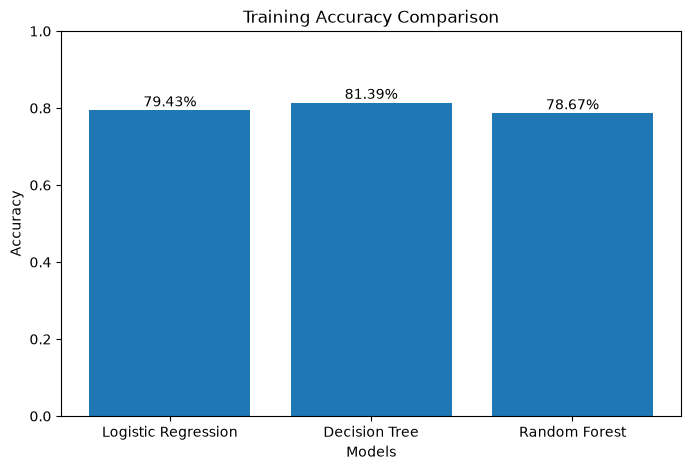

In [22]:

import matplotlib.pyplot as plt

model_names = [
    "Logistic Regression",
    "Decision Tree",
    "Random Forest"
]

training_accuracies = [0.7943, 0.8139, 0.7867]

plt.figure(figsize=(8, 5))

plt.bar(model_names, training_accuracies)

plt.title("Training Accuracy Comparison")
plt.xlabel("Models")
plt.ylabel("Accuracy")
plt.ylim(0, 1)

for i, value in enumerate(training_accuracies):
    plt.text(i, value + 0.01, f"{value:.2%}", ha="center")

plt.show()

### Model performance metrics visualization

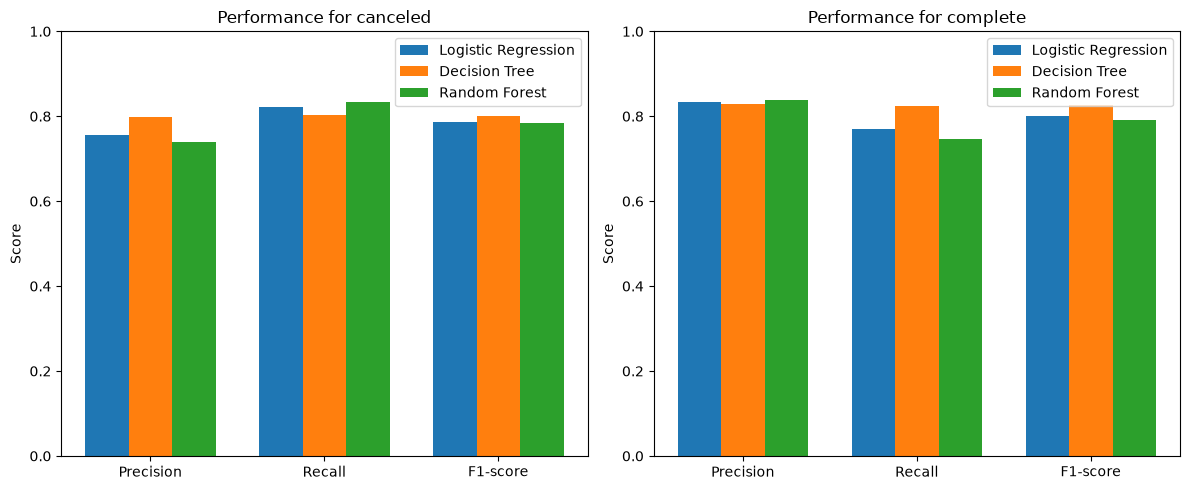

In [23]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import precision_score, recall_score, f1_score

models = {
    "Logistic Regression": baseline_pipeline,
    "Decision Tree": decision_tree_pipeline,
    "Random Forest": random_forest_pipeline
}

classes = ["canceled", "complete"]
metrics = ["Precision", "Recall", "F1-score"]

results = {}

for name, model in models.items():
    predictions = model.predict(X_train)

    results[name] = [
        [
            precision_score(y_train, predictions, pos_label=label),
            recall_score(y_train, predictions, pos_label=label),
            f1_score(y_train, predictions, pos_label=label)
        ]
        for label in classes
    ]

# Create separate charts for each class
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

x = np.arange(len(metrics))
width = 0.25

for ax, class_index, class_name in zip(axes, [0, 1], classes):
    for i, (model_name, scores) in enumerate(results.items()):
        values = scores[class_index]
        ax.bar(x + (i - 1) * width, values, width, label=model_name)

    ax.set_title(f"Performance for {class_name}")
    ax.set_xticks(x)
    ax.set_xticklabels(metrics)
    ax.set_ylim(0, 1)
    ax.set_ylabel("Score")
    ax.legend()

plt.tight_layout()
plt.show()

### Cross-validation comparison

In [24]:
from sklearn.model_selection import StratifiedGroupKFold, cross_validate
from sklearn.metrics import make_scorer, precision_score, recall_score, f1_score

cv = StratifiedGroupKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

scoring = {
    "accuracy": "accuracy",
    "precision": make_scorer(precision_score, pos_label="canceled"),
    "recall": make_scorer(recall_score, pos_label="canceled"),
    "f1": make_scorer(f1_score, pos_label="canceled"),
    "roc_auc": "roc_auc"
}

In [25]:
import pandas as pd

models = {
    "Logistic Regression": baseline_pipeline,
    "Decision Tree": decision_tree_pipeline,
    "Random Forest": random_forest_pipeline
}

cv_results = []

for name, model in models.items():

    print(f"Evaluating {name}...")

    scores = cross_validate(
        model,
        X_train,
        y_train,
        groups=groups_train,
        cv=cv,
        scoring=scoring,
        n_jobs=1
    )

    cv_results.append({
        "Model": name,
        "Accuracy": scores["test_accuracy"].mean(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1-score": scores["test_f1"].mean(),
        "ROC-AUC": scores["test_roc_auc"].mean()
    })

cv_results_df = pd.DataFrame(cv_results)

print("\nCross-Validation Results:")
display(cv_results_df.round(4))

Evaluating Logistic Regression...
Evaluating Decision Tree...
Evaluating Random Forest...

Cross-Validation Results:


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,0.7903,0.7503,0.8200,0.7836,0.8710
1,Decision Tree,0.8039,0.7791,0.8050,0.7916,0.8939
2,Random Forest,0.7810,0.7465,0.7979,0.7713,0.8633


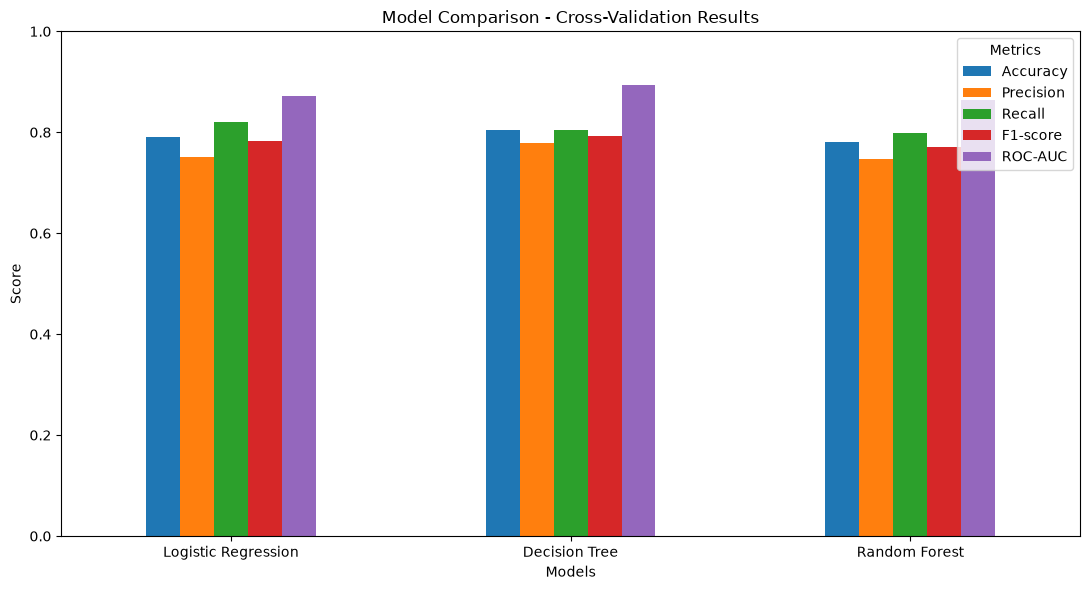

In [26]:
import matplotlib.pyplot as plt

metrics = ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]

cv_results_df.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Model Comparison - Cross-Validation Results")
plt.ylabel("Score")
plt.xlabel("Models")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title="Metrics")
plt.tight_layout()
plt.show()

### Cross-Validation Model Comparison

Three classification models were evaluated using 3-fold
Stratified Group Cross-Validation.

The Decision Tree achieved the highest average accuracy
(80.39%), F1-score (79.16%), and ROC-AUC (89.39%).

Logistic Regression achieved the highest recall (82.00%),
indicating better identification of canceled orders.

Based on the overall F1-score and ROC-AUC, the Decision Tree
was selected as the provisional best-performing model.

The Random Forest achieved comparatively lower scores
across the evaluated metrics.

Final model performance will be assessed using the
held-out test dataset.

In [27]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

# Generate predictions
y_pred = decision_tree_pipeline.predict(X_test)

# Calculate prediction probabilities
y_proba = decision_tree_pipeline.predict_proba(X_test)

# Final evaluation
print("Final Test Accuracy:",
      round(accuracy_score(y_test, y_pred), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# ROC-AUC for canceled orders
canceled_index = list(decision_tree_pipeline.classes_).index("canceled")

roc_auc = roc_auc_score(
    (y_test == "canceled").astype(int),
    y_proba[:, canceled_index]
)

print("Test ROC-AUC:", round(roc_auc, 4))

# Confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(
    y_test,
    y_pred,
    labels=["canceled", "complete"]
))

Final Test Accuracy: 0.8029

Classification Report:
              precision    recall  f1-score   support

    canceled       0.79      0.79      0.79     40450
    complete       0.82      0.82      0.82     47045

    accuracy                           0.80     87495
   macro avg       0.80      0.80      0.80     87495
weighted avg       0.80      0.80      0.80     87495

Test ROC-AUC: 0.8965

Confusion Matrix:
[[31877  8573]
 [ 8675 38370]]


In [4]:
import pandas as pd

# Get feature names after preprocessing
feature_names = (
    print(decision_tree_pipeline.named_steps.keys())
    .get_feature_names_out()
)

# Get trained Decision Tree model
tree_model = decision_tree_pipeline.named_steps["classifier"]

# Calculate feature importance
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": tree_model.feature_importances_
})

# Sort by importance
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print("Top 20 Important Features:")
display(importance_df.head(20))

NameError: name 'decision_tree_pipeline' is not defined

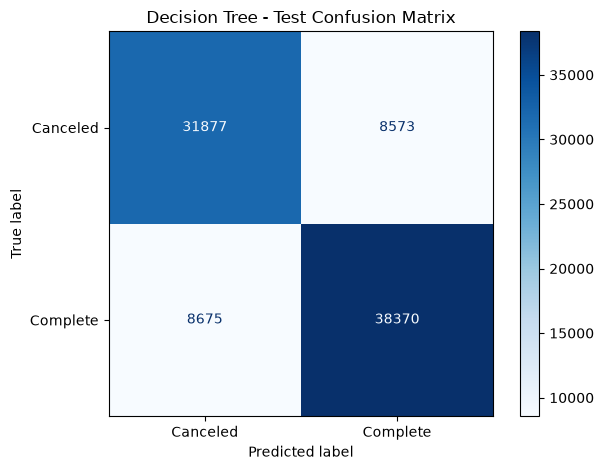

In [28]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["canceled", "complete"]
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Canceled", "Complete"]
)

display.plot(cmap="Blues", values_format="d")

plt.title("Decision Tree - Test Confusion Matrix")
plt.tight_layout()
plt.show()

### Final Test Evaluation

The selected Decision Tree model was evaluated on the
held-out test dataset containing 87,495 records.

The model achieved 80.29% accuracy and a ROC-AUC score
of 89.65%.

It correctly classified 31,877 canceled orders and
38,370 completed orders.

However, 8,573 canceled orders were incorrectly
classified as complete, while 8,675 complete orders
were incorrectly classified as canceled.

The results indicate reasonably consistent performance
between cross-validation and the final test evaluation.

## Error Analysis
### Step 1: Create a DataFrame containing actual and predicted results.

In [33]:
from IPython.display import display as show_display
error_analysis = X_test.copy()

error_analysis["Actual_Status"] = y_test
error_analysis["Predicted_Status"] = y_pred

# Filter incorrectly classified records
misclassified = error_analysis[
    error_analysis["Actual_Status"] !=
    error_analysis["Predicted_Status"]
]

print("Total test records:", len(error_analysis))
print("Misclassified records:", len(misclassified))

print(
    "Misclassification rate:",
    round(len(misclassified) / len(error_analysis) * 100, 2),
    "%"
)

show_display(misclassified.head(10))

Total test records: 87495
Misclassified records: 17248
Misclassification rate: 19.71 %


,sku,price,qty_ordered,grand_total,category_name_1,discount_amount,payment_method,order_year,order_month,customer_year,customer_month,customer_tenure_months,Actual_Status,Predicted_Status
5,UK_Namkino All In One 200 Gms,80.00,1,80.00,Soghaat,0.0,cod,2016,7,2016,7,0,canceled,complete
19,RL_B005,899.25,1,2118.25,Home & Living,0.0,cod,2016,7,2016,7,0,canceled,complete
20,bed&rest_S7,899.00,1,2118.25,Home & Living,0.0,cod,2016,7,2016,7,0,canceled,complete
21,L&L_LLHLE8224S,320.00,1,2118.25,Home & Living,0.0,cod,2016,7,2016,7,0,canceled,complete
48,RS_Sohan Halwa Tin,300.00,2,2210.00,Soghaat,0.0,cod,2016,7,2016,7,0,canceled,complete
49,UK_Soan Papdi Original 250 Gms,150.00,2,2210.00,Soghaat,0.0,cod,2016,7,2016,7,0,canceled,complete
50,UK_Gift Box Soghaat 500 Gms,465.00,2,2210.00,Soghaat,0.0,cod,2016,7,2016,7,0,canceled,complete
51,RS_Double Delight,380.00,1,2210.00,Soghaat,0.0,cod,2016,7,2016,7,0,canceled,complete
196,Huawei Honor 4C,16460.00,1,16460.00,Mobiles & Tablets,0.0,cod,2016,7,2016,7,0,canceled,complete
237,emo_HST-17030-B-M,550.00,1,900.00,Men's Fashion,0.0,cod,2016,7,2016,7,0,canceled,complete


### Step 2: Examine the types of mistakes.

In [35]:
print("Actual vs Predicted Status:")

show_display(
    misclassified.groupby(
        ["Actual_Status", "Predicted_Status"]
    ).size().reset_index(name="Count")
)

Actual vs Predicted Status:


,Actual_Status,Predicted_Status,Count
0,canceled,complete,8573
1,complete,canceled,8675


### actual vs predicted summary

In [37]:
error_summary = pd.crosstab(
    misclassified["Actual_Status"],
    misclassified["Predicted_Status"]
)

show_display(error_summary)

Predicted_Status,canceled,complete
Actual_Status,,
canceled,0,8573
complete,8675,0


### Analyze errors by payment method

In [39]:
payment_errors = misclassified.groupby(
    ["Actual_Status", "payment_method"]
).size().reset_index(name="Error_Count")

show_display(
    payment_errors.sort_values(
        "Error_Count",
        ascending=False
    ).head(10)
)

,Actual_Status,payment_method,Error_Count
13,complete,Payaxis,3436
4,canceled,cod,2881
0,canceled,Easypay,1819
11,complete,Easypay,1698
8,canceled,jazzwallet,1206
21,complete,jazzwallet,1127
6,canceled,easypay_voucher,1043
2,canceled,Payaxis,873
16,complete,cod,735
18,complete,easypay_voucher,616


### Analyze errors by product category

In [41]:
category_errors = misclassified.groupby(
    ["Actual_Status", "category_name_1"]
).size().reset_index(name="Error_Count")

show_display(
    category_errors.sort_values(
        "Error_Count",
        ascending=False
    ).head(10)
)

,Actual_Status,category_name_1,Error_Count
9,canceled,Mobiles & Tablets,2063
24,complete,Mobiles & Tablets,1972
15,complete,Appliances,1214
0,canceled,Appliances,1135
13,canceled,Superstore,909
28,complete,Superstore,864
8,canceled,Men's Fashion,785
23,complete,Men's Fashion,784
29,complete,Women's Fashion,782
14,canceled,Women's Fashion,756


In [43]:
# Mark incorrect predictions
error_analysis["Is_Error"] = (
    error_analysis["Actual_Status"] !=
    error_analysis["Predicted_Status"]
)

# Error rate by payment method
payment_error_rates = (
    error_analysis.groupby("payment_method")["Is_Error"]
    .agg(["sum", "count", "mean"])
    .reset_index()
)

payment_error_rates.columns = [
    "Payment_Method",
    "Error_Count",
    "Total_Records",
    "Error_Rate"
]

payment_error_rates["Error_Rate"] *= 100

show_display(
    payment_error_rates.sort_values(
        "Error_Rate", ascending=False
    ).round(2)
)

,Payment_Method,Error_Count,Total_Records,Error_Rate
12,marketingexpense,5,5,100.00
11,jazzwallet,2333,6048,38.57
9,internetbanking,40,110,36.36
10,jazzvoucher,882,2528,34.89
8,easypay_voucher,1659,5615,29.55
1,Easypay_MA,730,2520,28.97
2,Payaxis,4309,16766,25.70
0,Easypay,3517,14369,24.48
16,ublcreditcard,41,187,21.93
6,cod,3616,34504,10.48


In [45]:
category_error_rates = (
    error_analysis.groupby("category_name_1")["Is_Error"]
    .agg(["sum", "count", "mean"])
    .reset_index()
)

category_error_rates.columns = [
    "Category",
    "Error_Count",
    "Total_Records",
    "Error_Rate"
]

category_error_rates["Error_Rate"] *= 100

show_display(
    category_error_rates.sort_values(
        "Error_Rate", ascending=False
    ).round(2)
)

,Category,Error_Count,Total_Records,Error_Rate
3,Computing,730,2578,28.32
13,Superstore,1773,6369,27.84
0,Appliances,2349,8492,27.66
4,Entertainment,1165,4436,26.26
9,Mobiles & Tablets,4035,18979,21.26
6,Home & Living,717,3684,19.46
14,Women's Fashion,1538,8066,19.07
1,Beauty & Grooming,1129,6065,18.62
5,Health & Sports,375,2399,15.63
7,Kids & Baby,334,2342,14.26


### Error Analysis Findings

The Decision Tree model incorrectly classified 17,248 out of 87,495 test records, resulting in a misclassification rate of 19.71%.

The payment method analysis showed relatively high error rates for Jazzwallet (38.57%), Internet Banking (36.36%) and Jazzvoucher (34.89%). In comparison, Cash on Delivery (COD) had an error rate of 10.48%.

The product category analysis showed higher error rates in Computing (28.32%), Superstore (27.84%) and Appliances (27.66%). Men's Fashion and Soghaat had comparatively lower error rates of 12.85% and 12.42%, respectively.

These findings suggest that prediction errors vary across payment methods and product categories. However, small sample sizes and differences in category distributions must be considered before drawing conclusions.

Further investigation and additional data may help improve predictions for categories and payment methods with higher error rates.

### Model Limitations and Assumptions

**Limitations:**

1. The model achieved 80.29% test accuracy, meaning some orders are still incorrectly classified.
2. Prediction errors vary across payment methods and product categories.
3. Some payment methods have very few records, making their error rates less reliable.
4. The dataset contains item-level records, so evaluation reflects item-level rather than unique order-level performance.
5. The dataset represents historical e-commerce transactions from Pakistan, so performance on newer transactions or different markets may vary.

**Assumptions:**

1. Payment method is available before the final order status is determined.
2. Price, quantity, discount and grand total are known at prediction time.
3. Customer registration information is available when making predictions.
4. The historical relationship between transaction features and order status remains reasonably consistent.

**Intended Use:**

The model is intended as an experimental decision-support tool for identifying orders that may be canceled or completed. It should not automatically cancel orders or make final business decisions without further validation.

In [46]:
import joblib

joblib.dump(
    decision_tree_pipeline,
    "decision_tree_pipeline.joblib"
)

print("Decision Tree pipeline saved successfully.")

Decision Tree pipeline saved successfully.


In [47]:
import joblib

loaded_model = joblib.load("decision_tree_pipeline.joblib")

print("Saved model loaded successfully.")

Saved model loaded successfully.


In [49]:
new_records = X_test.head(5)

predictions = loaded_model.predict(new_records)

results = new_records.copy()
results["Predicted_Status"] = predictions

show_display(results)

,sku,price,qty_ordered,grand_total,category_name_1,discount_amount,payment_method,order_year,order_month,customer_year,customer_month,customer_tenure_months,Predicted_Status
0,kreations_YI 06-L,1950.00,1,1950.00,Women's Fashion,0.0,cod,2016,7,2016,7,0,complete
5,UK_Namkino All In One 200 Gms,80.00,1,80.00,Soghaat,0.0,cod,2016,7,2016,7,0,complete
6,kcc_krone deal,360.00,1,60.00,Beauty & Grooming,300.0,cod,2016,7,2016,7,0,complete
19,RL_B005,899.25,1,2118.25,Home & Living,0.0,cod,2016,7,2016,7,0,complete
20,bed&rest_S7,899.00,1,2118.25,Home & Living,0.0,cod,2016,7,2016,7,0,complete


In [51]:
comparison = pd.DataFrame({
    "Actual_Status": y_test.head(5).values,
    "Predicted_Status": predictions
})

show_display(comparison)


,Actual_Status,Predicted_Status
0,complete,complete
1,canceled,complete
2,complete,complete
3,canceled,complete
4,canceled,complete


The trained Decision Tree pipeline was saved using Joblib and successfully loaded. Predictions were generated on five unseen-to-training test records. This verified that the saved pipeline can be reused for inference. The sample predictions included both correct and incorrect classifications.

# Part B: End-to-End Tabular Machine Learning

## 1. Project Overview
This project develops a machine learning model to predict whether an e-commerce transaction will be completed or canceled using historical Pakistani e-commerce data.

## 2. Prediction Task
- **Problem type:** Binary Classification
- **Target variable:** `status`
- **Classes:** `complete` and `canceled`
- **Intended prediction point:** After order details and payment method are recorded, but before the final order status is known.

## 3. Dataset Summary
- **Filtered records:** 434,934
- **Unique orders:** 318,158
- **Training records:** 347,439
- **Testing records:** 87,495
- **Complete:** 53.73%
- **Canceled:** 46.27%

The dataset contains item-level transaction records. Multiple items can belong to the same order.

## 4. Data Leakage Prevention
The following columns were excluded:
- `BI Status`: Directly reveals information about the target.
- `increment_id`: Used for grouping during splitting, not as a predictor.
- `item_id`: Identifier rather than a useful predictive feature.
- `Working Date`: Duplicates `created_at`.
- `MV`: Meaning unclear and highly redundant with transaction totals.
- `sales_commission_code`: Contains approximately 81.89% missing values.
- Redundant date columns: `Year`, `Month`, `M-Y`, and `FY`.

## 5. Data Splitting
A GroupShuffleSplit with an 80:20 ratio was used. Records belonging to the same order were kept in the same split to prevent order-level overlap.

The training and testing class proportions were nearly identical.

## 6. Preprocessing
A Scikit-learn `ColumnTransformer` and `Pipeline` were used.

- Numerical features: Median imputation and standard scaling.
- Categorical features: Most-frequent imputation and one-hot encoding.
- Unknown categories were handled using `handle_unknown="ignore"`.
- Preprocessing was fitted on training data only.

## 7. Models Evaluated
Three classification models were trained:
1. Logistic Regression
2. Decision Tree
3. Random Forest

Three-fold StratifiedGroupKFold cross-validation was used.

## 8. Cross-Validation Results

| Model | Accuracy | Precision | Recall | F1-score | ROC-AUC |
|---|---:|---:|---:|---:|---:|
| Logistic Regression | 0.7903 | 0.7503 | 0.8200 | 0.7836 | 0.8710 |
| Decision Tree | 0.8039 | 0.7791 | 0.8050 | 0.7916 | 0.8939 |
| Random Forest | 0.7810 | 0.7465 | 0.7979 | 0.7713 | 0.8633 |

The Decision Tree was selected because it achieved the highest cross-validation accuracy, F1-score, and ROC-AUC.

## 9. Final Test Results
The selected Decision Tree model was evaluated on the untouched test set.

- **Accuracy:** 80.29%
- **ROC-AUC:** 0.8965
- **Canceled F1-score:** 0.79
- **Complete F1-score:** 0.82

### Confusion Matrix

| Actual / Predicted | Canceled | Complete |
|---|---:|---:|
| Canceled | 31,877 | 8,573 |
| Complete | 8,675 | 38,370 |

The model correctly classified 70,247 records and incorrectly classified 17,248 records.

## 10. Error Analysis
The model's overall test error rate was 19.71%.

Error rates varied across payment methods and product categories. Higher observed error rates occurred in Jazzwallet, Internet Banking, Jazzvoucher, Computing, Superstore, and Appliances.

Small subgroup sizes may make some error rates unreliable. These differences do not establish the causes of prediction errors.

## 11. Model Saving and Inference
The trained Decision Tree pipeline was saved using Joblib and successfully loaded.

Predictions were generated on five held-out test records to verify that the saved pipeline could be reused for inference.

## 12. Limitations
1. The model does not predict every transaction correctly.
2. Performance may change with newer transaction patterns.
3. Some payment methods and product categories have limited records.
4. Evaluation is item-level rather than unique-order-level.
5. Historical data may not represent current e-commerce behavior.

## 13. Assumptions and Intended Use
The model assumes that payment method, price, quantity, discount, grand total, and customer information are available before the final order status is determined.

It is intended as an experimental decision-support tool for identifying transactions that may be canceled or completed. It should not automatically cancel orders or make final business decisions without further validation.

## 14. Conclusion
Among the three evaluated models, Decision Tree achieved the strongest cross-validation performance. Its final test accuracy was 80.29%, with a ROC-AUC of 0.8965. The results demonstrate that transaction features contain useful information for predicting order status, although further validation and improvement are necessary before real-world deployment.